---
title: "Лабораторна робота 6. Верифікація і валідація моделі, аналіз чутливості та кількісне оцінювання невизначеності"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib
format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

ЛР5 завершилася артефактом *Calibration Specification v0.5*:

$$
\text{model}
\rightarrow
\text{calibration data}
\rightarrow
\hat{\theta}.
$$

Але calibrated model ще не є credible model.

У ЛР6 будуємо наступний рівень:

$$
\text{Calibration Specification v0.5}
\rightarrow
\text{Verification}
\rightarrow
\text{Validation}
\rightarrow
\text{Sensitivity}
\rightarrow
\text{UQ}
\rightarrow
\text{Model Credibility Report v0.6}.
$$

Методологічна основа V&V -- [@oberkampfRoy2010], sensitivity analysis -- [@saltelli2008], uncertainty quantification -- [@smith2024].
:::

# Мета роботи

Набути практичної здатності формувати evidence щодо достовірності computational model: виконувати code і solution verification, відокремлювати calibration від validation, визначати intended use та Quantity of Interest, проводити local і global sensitivity analysis, поширювати parameter uncertainty на model outputs методом Monte Carlo та формулювати обмежений credibility statement.

# Завдання роботи

1. Відновити calibrated model із ЛР5.
2. Сформувати verification plan.
3. Виконати code verification на analytical benchmark.
4. Виконати solution verification через refinement study.
5. Відокремити calibration та validation data.
6. Визначити intended use і Quantity of Interest.
7. Провести validation за незалежними synthetic observations.
8. Дослідити domain of validity.
9. Виконати local sensitivity analysis.
10. Виконати global sensitivity screening.
11. Задати distributions uncertain parameters.
12. Провести Monte Carlo uncertainty propagation.
13. Побудувати uncertainty interval для trajectory і QoI.
14. Сформувати uncertainty budget.
15. Перенести workflow на дисертаційний об'єкт.
16. Сформувати *Model Credibility Report v0.6*.

# Теоретичний мінімум

Нехай calibrated model має parameter estimate

$$
\hat{\theta}.
$$

Її credibility не визначається одним показником:

$$
\mathcal{C}
=
\mathcal{C}
(
E_{ver},
E_{val},
E_{sens},
E_{UQ},
U,
\Omega
),
$$

де:

- $E_{ver}$ -- verification evidence;
- $E_{val}$ -- validation evidence;
- $E_{sens}$ -- sensitivity evidence;
- $E_{UQ}$ -- uncertainty evidence;
- $U$ -- intended use;
- $\Omega$ -- domain of validity.

## Логіка роботи

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Calibrated<br/>model") --> B("Code + solution<br/>verification")
 B --> C("Independent<br/>validation")
 C --> D("Sensitivity<br/>analysis")
 D --> E("Uncertainty<br/>propagation")
 E --> F("Credibility<br/>statement")
 F --> G("Model Credibility<br/>Report v0.6")
```

# Частина I. Навчальний кейс

Продовжуємо logistic ODE з ЛР5:

$$
\frac{dx}{dt}
=
rx
\left(
1-\frac{x}{K}
\right).
$$

Для synthetic experiment відомі:

$$
r^*=0.8,
\qquad
K^*=100,
\qquad
x(0)=5.
$$

Але в calibration workflow ці значення вважаємо прихованими.

# 1. Імпорт бібліотек і параметри відтворюваності

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize

BASE_SEED = 42
rng = np.random.default_rng(BASE_SEED)

R_TRUE = 0.8
K_TRUE = 100.0
X0 = 5.0
SIGMA_OBS = 2.0

# 2. Computational model

Для logistic equation існує analytical solution:

$$
x(t)
=
\frac{K}
{
1+
\left(
\frac{K-x_0}{x_0}
\right)
e^{-rt}
}.
$$

Це дає нам benchmark для code verification.

In [2]:
def logistic_rhs(t, x, r, K):
    return r * x * (1 - x / K)

def simulate_logistic(t, r, K, x0):
    solution = solve_ivp(
        fun=lambda tau, x:
            logistic_rhs(tau, x, r, K),
        t_span=(float(t[0]), float(t[-1])),
        y0=[x0],
        t_eval=t,
        rtol=1e-9,
        atol=1e-11
    )
    if not solution.success:
        raise RuntimeError("ODE solver failed")
    return solution.y[0]

def logistic_exact(t, r, K, x0):
    factor = (K - x0) / x0
    return K / (1 + factor * np.exp(-r * t))

# 3. Code verification

Перевіримо numerical implementation відносно analytical benchmark.

Verification question:

> Чи відтворює `simulate_logistic()` відоме analytical solution у межах заданої numerical tolerance?

In [3]:
t_verify = np.linspace(0.0, 10.0, 101)

x_num = simulate_logistic(
    t_verify,
    R_TRUE,
    K_TRUE,
    X0
)

x_exact = logistic_exact(
    t_verify,
    R_TRUE,
    K_TRUE,
    X0
)

verification_error = np.max(
    np.abs(x_num - x_exact)
)

print(
    "Max absolute verification error:",
    f"{verification_error:.3e}"
)

assert verification_error < 1e-5

Max absolute verification error: 6.140e-07


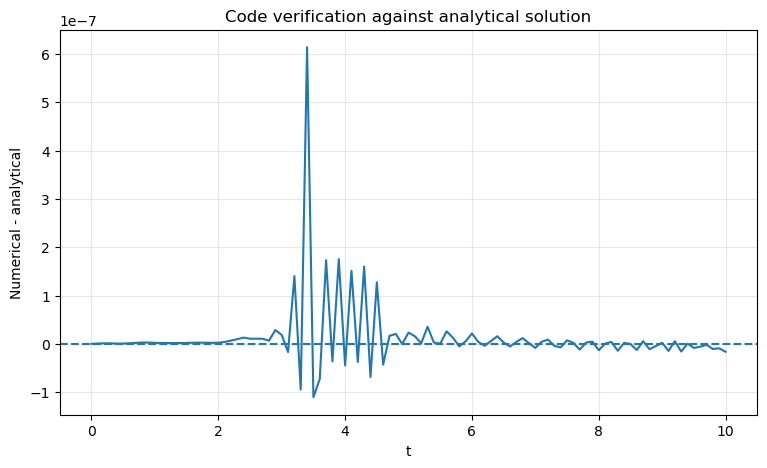

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(
    t_verify,
    x_num - x_exact
)
plt.axhline(
    0.0,
    linestyle="--"
)
plt.xlabel("t")
plt.ylabel("Numerical - analytical")
plt.title("Code verification against analytical solution")
plt.grid(alpha=0.3)
plt.show()

::: callout-tip
## Інтерпретація

Малий error тут є evidence про implementation конкретної mathematical model.

Він *не* є validation evidence щодо реальної системи.
:::

# 4. Solution verification

Щоб явно дослідити discretization error, реалізуємо simple explicit Euler:

$$
x_{n+1}
=
x_n
+
h
r x_n
\left(
1-\frac{x_n}{K}
\right).
$$

Для first-order method очікуємо:

$$
E(h)
\approx
Ch.
$$

In [5]:
def logistic_euler(T, h, r, K, x0):
    n_steps = int(round(T / h))
    x = x0

    for _ in range(n_steps):
        x = x + h * r * x * (1 - x / K)

    return x

T_VERIFY = 4.0
exact_T = logistic_exact(
    np.array([T_VERIFY]),
    R_TRUE,
    K_TRUE,
    X0
)[0]

step_sizes = np.array([
    0.4,
    0.2,
    0.1,
    0.05,
    0.025
])

solution_errors = np.array([
    abs(
        logistic_euler(
            T_VERIFY,
            h,
            R_TRUE,
            K_TRUE,
            X0
        )
        - exact_T
    )
    for h in step_sizes
])

observed_orders = np.log(
    solution_errors[:-1]
    / solution_errors[1:]
) / np.log(
    step_sizes[:-1]
    / step_sizes[1:]
)

pd.DataFrame({
    "h": step_sizes,
    "error": solution_errors,
    "observed_order_to_next": np.r_[
        observed_orders,
        np.nan
    ]
})

,h,error,observed_order_to_next
0,0.400,6.557005,1.002127
1,0.200,3.273672,1.006590
2,0.100,1.629377,1.004660
3,0.050,0.812061,1.002665
4,0.025,0.405281,NaN


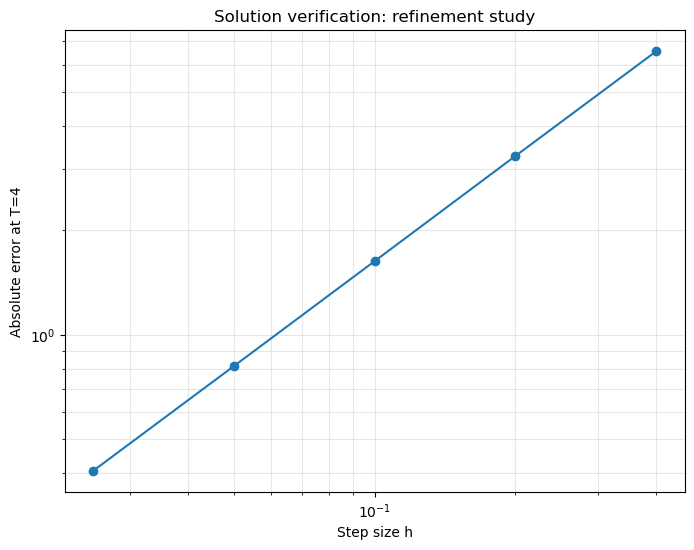

In [6]:
plt.figure(figsize=(8, 6))
plt.loglog(
    step_sizes,
    solution_errors,
    marker="o"
)
plt.xlabel("Step size h")
plt.ylabel("Absolute error at T=4")
plt.title("Solution verification: refinement study")
plt.grid(alpha=0.3, which="both")
plt.show()

## Завдання 4.1

Поясніть:

1. чи зменшується error при refinement;
2. чи наближається observed order до $p=1$;
3. чому це є solution verification, а не validation;
4. який $h$ Ви вважали б достатнім для конкретного QoI.

# 5. Calibration data і validation data

Створимо два незалежні synthetic datasets.

Calibration data:

$$
D_{cal}
=
\{(t_i,y_i^{cal})\}.
$$

Validation data:

$$
D_{val}
=
\{(t_j,y_j^{val})\}.
$$

Noise realizations різні.

In [7]:
rng_cal = np.random.default_rng(101)
rng_val = np.random.default_rng(202)

t_cal = np.linspace(
    0.0,
    7.0,
    15
)

t_val = np.linspace(
    7.5,
    10.0,
    6
)

y_cal_true = logistic_exact(
    t_cal,
    R_TRUE,
    K_TRUE,
    X0
)

y_val_true = logistic_exact(
    t_val,
    R_TRUE,
    K_TRUE,
    X0
)

y_cal = (
    y_cal_true
    + rng_cal.normal(
        0.0,
        SIGMA_OBS,
        len(t_cal)
    )
)

y_val = (
    y_val_true
    + rng_val.normal(
        0.0,
        SIGMA_OBS,
        len(t_val)
    )
)

# 6. Калібрування лише на $D_{cal}$

Використовуємо

$$
J(r,K)
=
\sum_i
\left[
y_i^{cal}
-
x(t_i;r,K)
\right]^2.
$$

Validation data в optimizer не передаємо.

In [8]:
def calibration_loss(params):
    r, K = params

    if r <= 0 or K <= 0:
        return np.inf

    prediction = logistic_exact(
        t_cal,
        r,
        K,
        X0
    )

    return np.sum(
        (y_cal - prediction) ** 2
    )

fit = minimize(
    calibration_loss,
    x0=np.array([0.5, 80.0]),
    method="L-BFGS-B",
    bounds=[
        (0.05, 2.0),
        (20.0, 200.0)
    ]
)

R_HAT, K_HAT = fit.x

print(
    "Estimated r:",
    round(R_HAT, 4)
)
print(
    "Estimated K:",
    round(K_HAT, 4)
)

Estimated r: 0.8276
Estimated K: 96.6383


# 7. Intended use і QoI

Для навчального кейсу задаємо intended use:

> *Прогнозувати стан системи на часовому горизонті $0\le t\le10$ та оцінювати час досягнення рівня $x=80$.*

Визначимо QoI:

$$
Q_1=x(10),
$$

$$
Q_2=t_{80}
=
\min
\{
t:x(t)\ge80
\}.
$$

Validation має оцінювати саме evidence, релевантне цим quantities.

In [9]:
def threshold_time(
    r,
    K,
    x0,
    threshold=80.0,
    t_max=20.0
):
    t_dense = np.linspace(
        0.0,
        t_max,
        4001
    )

    trajectory = logistic_exact(
        t_dense,
        r,
        K,
        x0
    )

    reached = np.where(
        trajectory >= threshold
    )[0]

    if len(reached) == 0:
        return np.nan

    return t_dense[reached[0]]

q1_hat = logistic_exact(
    np.array([10.0]),
    R_HAT,
    K_HAT,
    X0
)[0]

q2_hat = threshold_time(
    R_HAT,
    K_HAT,
    X0
)

print("Predicted Q1 = x(10):", round(q1_hat, 4))
print("Predicted Q2 = t80:", round(q2_hat, 4))

Predicted Q1 = x(10): 96.1897
Predicted Q2 = t80: 5.415


# 8. Independent validation

Порівняємо prediction calibrated model із $D_{val}$.

$$
RMSE_{val}
=
\sqrt{
\frac{1}{n_{val}}
\sum_j
\left[
y_j^{val}
-
\hat y_j
\right]^2
}.
$$

Validation RMSE: 3.6658


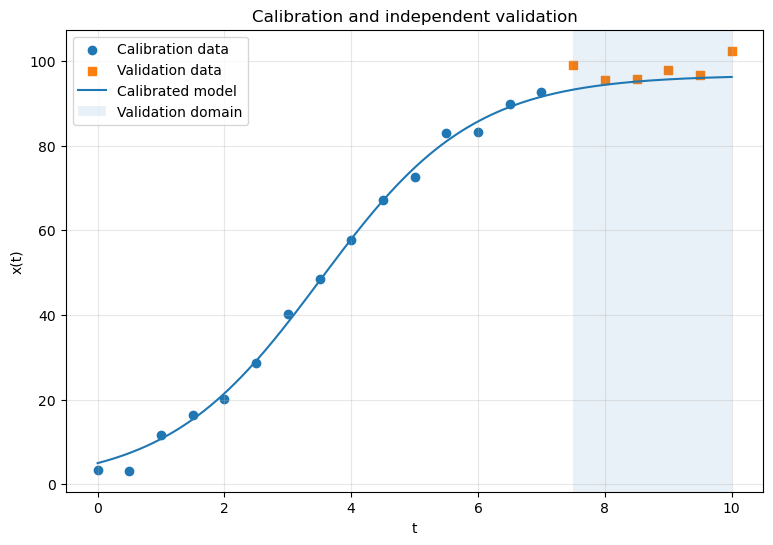

In [10]:
y_val_pred = logistic_exact(
    t_val,
    R_HAT,
    K_HAT,
    X0
)

rmse_val = np.sqrt(
    np.mean(
        (y_val - y_val_pred) ** 2
    )
)

print(
    "Validation RMSE:",
    round(rmse_val, 4)
)

plt.figure(figsize=(9, 6))
plt.scatter(
    t_cal,
    y_cal,
    label="Calibration data"
)
plt.scatter(
    t_val,
    y_val,
    marker="s",
    label="Validation data"
)

t_dense = np.linspace(
    0.0,
    10.0,
    300
)

plt.plot(
    t_dense,
    logistic_exact(
        t_dense,
        R_HAT,
        K_HAT,
        X0
    ),
    label="Calibrated model"
)

plt.axvspan(
    7.5,
    10.0,
    alpha=0.1,
    label="Validation domain"
)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Calibration and independent validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 8.1

Сформулюйте validation statement без фрази «модель валідована».

Вкажіть:

- intended use;
- QoI;
- validation interval;
- metric;
- observed discrepancy;
- limitations.

# 9. Domain of validity

У нашому experiment validation evidence отримано для

$$
7.5\le t\le10.
$$

Це не дає автоматичного evidence для

$$
t>10.
$$

Побудуємо extrapolation до $t=15$, але позначимо її інший epistemic status.

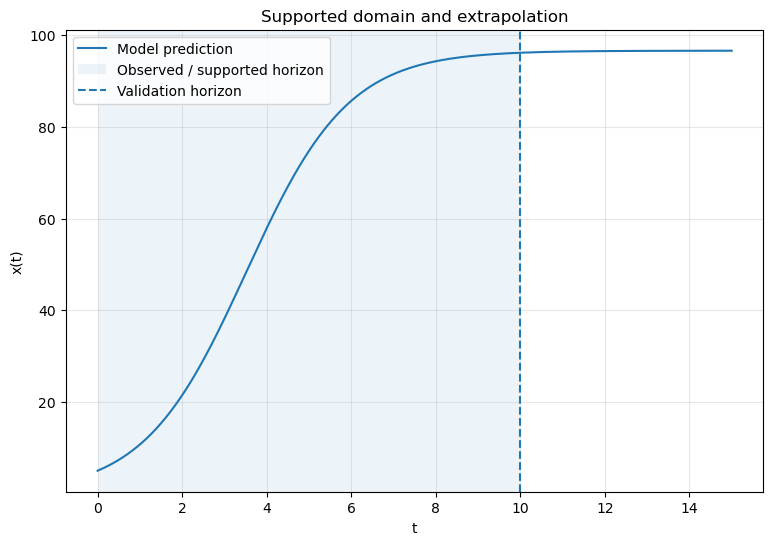

In [11]:
t_extended = np.linspace(
    0.0,
    15.0,
    400
)

x_extended = logistic_exact(
    t_extended,
    R_HAT,
    K_HAT,
    X0
)

plt.figure(figsize=(9, 6))
plt.plot(
    t_extended,
    x_extended,
    label="Model prediction"
)
plt.axvspan(
    0.0,
    10.0,
    alpha=0.08,
    label="Observed / supported horizon"
)
plt.axvline(
    10.0,
    linestyle="--",
    label="Validation horizon"
)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Supported domain and extrapolation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 10. Аналіз чутливості (Sensitivity Analysis)

Sensitivity analysis відповідає на питання:

> *Як зміни inputs / parameters впливають на model output?*

Це не те саме, що uncertainty quantification.

$$
\text{Sensitivity Analysis}
\neq
\text{Uncertainty Quantification}.
$$

Sensitivity визначає *вплив*.

UQ визначає *невизначеність output*, породжену невизначеністю inputs [@saltelli2008; @smith2024].

# 11. Local sensitivity

Для QoI

$$
Q(\theta)
$$

local sensitivity parameter $\theta_j$ можна оцінити finite difference:

$$
S_j
\approx
\frac{
Q(\theta_j+\Delta\theta_j)
-
Q(\theta_j-\Delta\theta_j)
}{
2\Delta\theta_j
}.
$$

Щоб parameters різних units можна було порівнювати, використаємо normalized sensitivity:

$$
S_j^{norm}
=
\frac{\theta_j}{Q}
\frac{\partial Q}{\partial\theta_j}.
$$

In [12]:
def q1(r, K):
    return logistic_exact(
        np.array([10.0]),
        r,
        K,
        X0
    )[0]

def normalized_local_sensitivity(
    parameter_name,
    relative_step=0.01
):
    q_base = q1(
        R_HAT,
        K_HAT
    )

    if parameter_name == "r":
        delta = relative_step * R_HAT

        q_plus = q1(
            R_HAT + delta,
            K_HAT
        )
        q_minus = q1(
            R_HAT - delta,
            K_HAT
        )

        derivative = (
            q_plus - q_minus
        ) / (2 * delta)

        return (
            R_HAT / q_base
        ) * derivative

    delta = relative_step * K_HAT

    q_plus = q1(
        R_HAT,
        K_HAT + delta
    )
    q_minus = q1(
        R_HAT,
        K_HAT - delta
    )

    derivative = (
        q_plus - q_minus
    ) / (2 * delta)

    return (
        K_HAT / q_base
    ) * derivative

local_sensitivity = pd.Series({
    "r": normalized_local_sensitivity("r"),
    "K": normalized_local_sensitivity("K")
})

local_sensitivity

r    0.038465
K    0.995104
dtype: float64

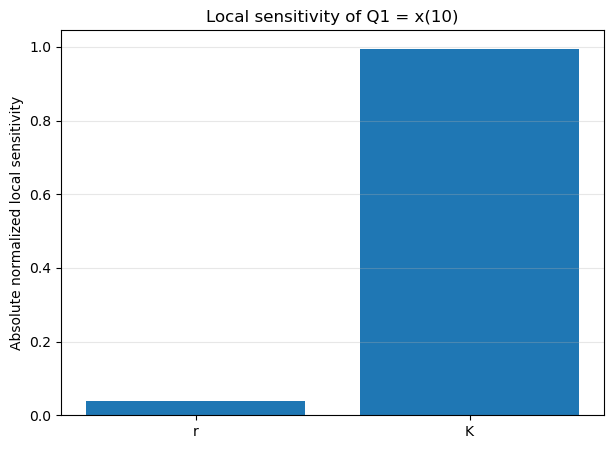

In [13]:
plt.figure(figsize=(7, 5))
plt.bar(
    local_sensitivity.index,
    np.abs(local_sensitivity.values)
)
plt.ylabel(
    "Absolute normalized local sensitivity"
)
plt.title(
    "Local sensitivity of Q1 = x(10)"
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.show()

## Завдання 11.1

Поясніть:

1. який parameter локально сильніше впливає на $Q_1$;
2. чи можна переносити цей ranking на інші QoI;
3. чому local sensitivity залежить від operating point;
4. чому local sensitivity не описує interaction effects у всьому parameter space.

# 12. Global sensitivity screening

Для повного global sensitivity analysis існують variance-based methods, зокрема Sobol indices [@saltelli2008].

У цій роботі спочатку виконаємо простий *global screening*: одночасно sampling parameters у всьому заданому uncertainty domain і оцінимо rank correlation із QoI.

Це не заміна Sobol analysis, а прозорий вступ до global sensitivity.

In [14]:
rng_global = np.random.default_rng(303)

N_GLOBAL = 3000

r_global = rng_global.uniform(
    0.9 * R_HAT,
    1.1 * R_HAT,
    N_GLOBAL
)

K_global = rng_global.uniform(
    0.9 * K_HAT,
    1.1 * K_HAT,
    N_GLOBAL
)

q1_global = np.array([
    q1(r, K)
    for r, K in zip(
        r_global,
        K_global
    )
])

global_df = pd.DataFrame({
    "r": r_global,
    "K": K_global,
    "Q1": q1_global
})

rank_corr = global_df.rank().corr()["Q1"].drop("Q1")

rank_corr

r    0.045665
K    0.999099
Name: Q1, dtype: float64

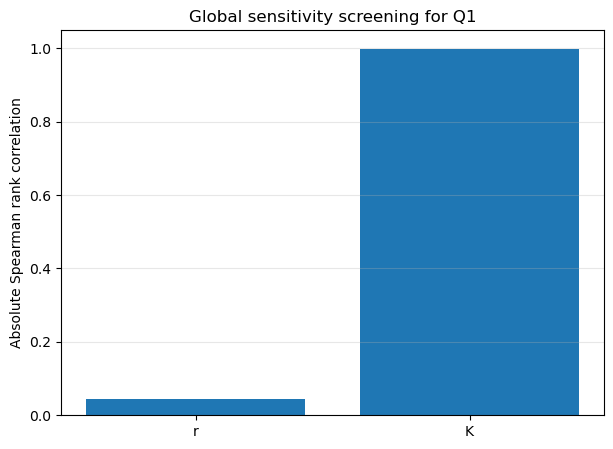

In [15]:
plt.figure(figsize=(7, 5))
plt.bar(
    rank_corr.index,
    np.abs(rank_corr.values)
)
plt.ylabel(
    "Absolute Spearman rank correlation"
)
plt.title(
    "Global sensitivity screening for Q1"
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.show()

::: callout-warning
## Важливо

Correlation-based screening:

- може виявляти monotonic influence;
- не є variance decomposition;
- не дає Sobol first-order / total-order indices;
- може бути недостатнім за strong nonlinear interactions.

Тому у звіті називаємо його саме *global sensitivity screening*.
:::

# 13. Кількісне оцінювання невизначеності (Uncertainty Quantification, UQ)

Тепер задаємо uncertainty model для parameters.

Для навчального прикладу припустимо:

$$
r
\sim
\mathcal{N}
(
\hat r,
(0.05\hat r)^2
),
$$

$$
K
\sim
\mathcal{N}
(
\hat K,
(0.05\hat K)^2
).
$$

Ці distributions є *assumptions навчального experiment*.

У реальному дослідженні вони мають походити з:

- parameter estimation uncertainty;
- posterior distribution;
- repeated experiments;
- expert knowledge;
- literature;
- measurement model.

# 14. Monte Carlo uncertainty propagation

Якщо

$$
\theta^{(m)}
\sim
p(\theta),
$$

то

$$
Q^{(m)}
=
Q
\left(
\theta^{(m)}
\right).
$$

Ensemble

$$
\{
Q^{(1)},\ldots,Q^{(M)}
\}
$$

наближує output distribution [@smith2024].

In [16]:
rng_uq = np.random.default_rng(404)

N_MC = 3000

r_mc = rng_uq.normal(
    R_HAT,
    0.05 * R_HAT,
    N_MC
)

K_mc = rng_uq.normal(
    K_HAT,
    0.05 * K_HAT,
    N_MC
)

valid = (
    (r_mc > 0)
    & (K_mc > 0)
)

r_mc = r_mc[valid]
K_mc = K_mc[valid]

t_uq = np.linspace(
    0.0,
    10.0,
    201
)

trajectories = np.array([
    logistic_exact(
        t_uq,
        r,
        K,
        X0
    )
    for r, K in zip(
        r_mc,
        K_mc
    )
])

median_trajectory = np.median(
    trajectories,
    axis=0
)

lower_trajectory = np.percentile(
    trajectories,
    5,
    axis=0
)

upper_trajectory = np.percentile(
    trajectories,
    95,
    axis=0
)

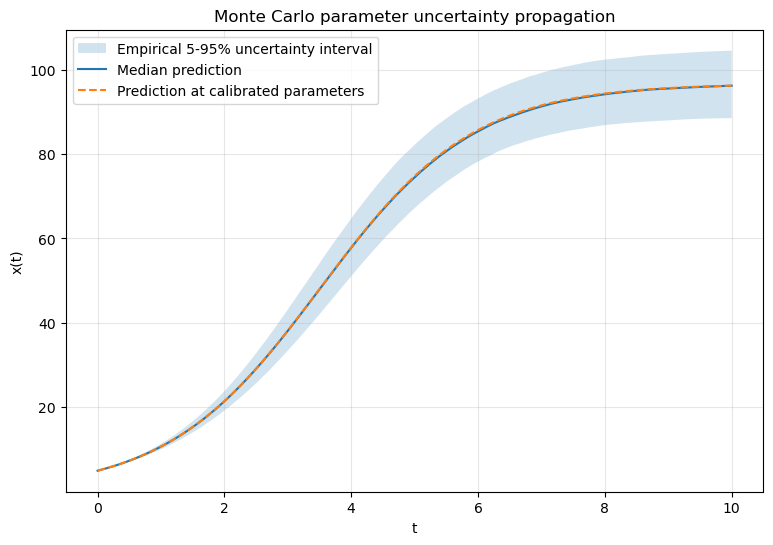

In [17]:
plt.figure(figsize=(9, 6))

plt.fill_between(
    t_uq,
    lower_trajectory,
    upper_trajectory,
    alpha=0.2,
    label="Empirical 5-95% uncertainty interval"
)

plt.plot(
    t_uq,
    median_trajectory,
    label="Median prediction"
)

plt.plot(
    t_uq,
    logistic_exact(
        t_uq,
        R_HAT,
        K_HAT,
        X0
    ),
    linestyle="--",
    label="Prediction at calibrated parameters"
)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Monte Carlo parameter uncertainty propagation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Ця 5--95% смуга є *empirical uncertainty interval* для заданої parameter uncertainty model.

Вона не є автоматично:

- confidence interval;
- Bayesian credible interval;
- prediction interval, що включає всі джерела uncertainty.

Ми propagate лише ті uncertainties, які явно включили.

# 15. UQ для QoI

Оцінимо distributions для

$$
Q_1=x(10)
$$

та

$$
Q_2=t_{80}.
$$

In [18]:
q1_mc = np.array([
    q1(r, K)
    for r, K in zip(
        r_mc,
        K_mc
    )
])

q2_mc = np.array([
    threshold_time(
        r,
        K,
        X0,
        threshold=80.0
    )
    for r, K in zip(
        r_mc,
        K_mc
    )
])

q2_finite = q2_mc[
    np.isfinite(q2_mc)
]

uq_summary = pd.DataFrame({
    "QoI": [
        "Q1 = x(10)",
        "Q2 = t80"
    ],
    "median": [
        np.median(q1_mc),
        np.median(q2_finite)
    ],
    "p05": [
        np.percentile(q1_mc, 5),
        np.percentile(q2_finite, 5)
    ],
    "p95": [
        np.percentile(q1_mc, 95),
        np.percentile(q2_finite, 95)
    ]
})

uq_summary.round(4)

,QoI,median,p05,p95
0,Q1 = x(10),96.1794,88.5078,104.4644
1,Q2 = t80,5.4400,4.8500,6.2400


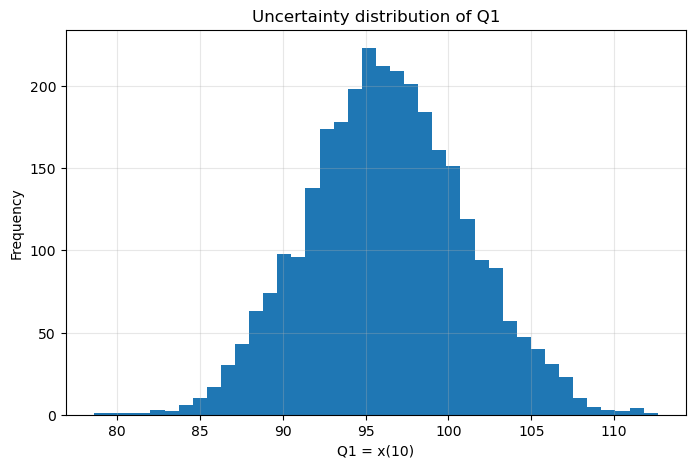

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(
    q1_mc,
    bins=40
)
plt.xlabel("Q1 = x(10)")
plt.ylabel("Frequency")
plt.title("Uncertainty distribution of Q1")
plt.grid(alpha=0.3)
plt.show()

# 16. Monte Carlo convergence

Monte Carlo result сам має sampling error.

Перевіримо, як стабілізується estimate

$$
E[Q_1]
$$

зі зростанням $M$.

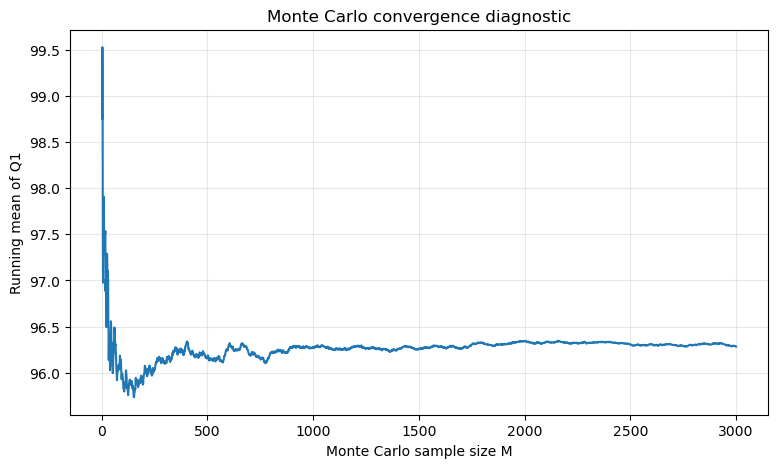

In [20]:
running_mean = np.cumsum(
    q1_mc
) / np.arange(
    1,
    len(q1_mc) + 1
)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(
        1,
        len(q1_mc) + 1
    ),
    running_mean
)
plt.xlabel("Monte Carlo sample size M")
plt.ylabel("Running mean of Q1")
plt.title("Monte Carlo convergence diagnostic")
plt.grid(alpha=0.3)
plt.show()

# 17. Uncertainty budget

Для реальної complex model потрібно явно перелічити uncertainty sources.

| Джерело | У ЛР6 враховано? | Як представлено? |
|---|---|---|
| observation noise | частково | synthetic validation data |
| parameter uncertainty | так | distributions для $r,K$ |
| initial-condition uncertainty | ні | fixed $x_0$ |
| numerical uncertainty | оцінено окремо | refinement study |
| model-form uncertainty | ні | лише обговорюється |
| structural uncertainty | ні | fixed logistic structure |
| scenario uncertainty | ні | fixed intended use |

Тому uncertainty interval із Monte Carlo не можна називати «повною невизначеністю моделі».

# 18. Sensitivity і UQ -- як вони пов'язані

Sensitivity analysis відповідає:

$$
\text{що найбільше впливає на }Q?
$$

UQ відповідає:

$$
\text{наскільки uncertain є }Q?
$$

Parameter може бути дуже influential, але майже точно відомим.

І навпаки, parameter може бути moderately influential, але дуже uncertain.

Тому priority для подальших measurements залежить від обох характеристик:

$$
\text{importance}
\approx
\text{sensitivity}
\times
\text{uncertainty}.
$$

Це conceptual relation, а не універсальна formula.

# 19. Credibility matrix навчального кейсу

| Компонент | Evidence | Результат | Обмеження |
|---|---|---|---|
| Code verification | analytical logistic solution | | |
| Solution verification | step refinement | | |
| Calibration | $D_{cal}$ | | |
| Validation | independent $D_{val}$ | | |
| Intended use | $x(t)$ до $t=10$, $t_{80}$ | | |
| Domain of validity | observed/validated horizon | | |
| Local sensitivity | normalized finite differences | | |
| Global sensitivity | rank-correlation screening | | |
| Parameter UQ | Monte Carlo | | |
| Numerical uncertainty | refinement evidence | | |
| Model-form uncertainty | not quantified | | |

# 20. Bounded credibility statement

Сформулюйте підсумок за шаблоном:

> Для intended use ________, Quantity of Interest ________ та domain ________ computational implementation пройшла ________. Validation comparison із ________ дала ________. Sensitivity analysis показав ________. За прийнятої parameter uncertainty model Monte Carlo propagation дала ________. Отриманий evidence підтримує використання model для ________, але не обґрунтовує ________.

Саме таке формулювання краще за безумовне:

> «Модель адекватна і валідована».

# Частина II. Перенесення на дисертаційне дослідження

# 21. Intended use

Сформулюйте одним реченням:

> Модель використовується для ...

Не використовуйте загальні формулювання на кшталт «для дослідження системи».

Вкажіть конкретний тип inference або prediction.

# 22. Quantity of Interest

Визначте щонайменше одну QoI:

$$
Q=Q(\theta,u,x_0).
$$

| QoI | Scientific meaning | Units | Intended use |
|---|---|---|---|
| $Q_1$ | | | |
| $Q_2$ | | | |

# 23. Verification plan

| Model component | Verification question | Test | Expected evidence |
|---|---|---|---|
| | | | |
| | | | |

Виконайте щонайменше:

- один code-level test;
- один numerical / computational consistency test.

Якщо analytical solution відсутнє, можливі:

- benchmark;
- invariant;
- limiting case;
- independent implementation;
- manufactured solution;
- convergence / refinement study.

# 24. Validation plan

| QoI | Validation data | Metric | Domain | Acceptance logic |
|---|---|---|---|---|
| | | | | |

Поясніть, чому validation evidence є релевантним intended use.

# 25. Domain of validity

Опишіть:

- input ranges;
- parameter ranges;
- temporal horizon;
- system regime;
- population / environment;
- topology class, якщо релевантно.

Явно відокремте interpolation від extrapolation.

# 26. Local sensitivity analysis

Оберіть ключові parameters

$$
\theta_1,\ldots,\theta_k
$$

і оцініть normalized local sensitivity для QoI.

Поясніть, чому саме цей operating point є релевантним.

# 27. Global sensitivity analysis

Визначте uncertainty ranges для parameters.

Для невеликої кількості parameters виконайте global screening або Sobol analysis.

Для Sobol analysis можна використати [SALib](https://salib.readthedocs.io/).

Якщо використовуєте screening, чітко назвіть його screening, а не variance decomposition.

# 28. Uncertainty model

Для кожного uncertain input:

| Input | Distribution / range | Source | Justification |
|---|---|---|---|
| $\theta_1$ | | | |
| $\theta_2$ | | | |

Не задавайте distribution лише тому, що normal distribution зручно sampling.

# 29. Monte Carlo propagation

Згенеруйте

$$
\theta^{(m)}
\sim
p(\theta)
$$

і обчисліть

$$
Q^{(m)}
=
Q(\theta^{(m)}).
$$

Побудуйте:

- distribution QoI;
- empirical uncertainty interval;
- convergence diagnostic.

# 30. Uncertainty budget

| Source | Aleatoric / epistemic | Quantified? | Method | Effect on QoI |
|---|---|---|---|---|
| data | | | | |
| parameters | | | | |
| initial state | | | | |
| numerical | | | | |
| model form | | | | |
| scenario | | | | |

# 31. Model Credibility Report v0.6

| Компонент | Специфікація / evidence |
|---|---|
| Research Question | |
| Intended use | |
| Quantity of Interest | |
| Model version | |
| Calibration artifact | Calibration Specification v0.5 |
| Code verification | |
| Solution verification | |
| Validation data | |
| Validation metric | |
| Validation result | |
| Domain of validity | |
| Extrapolation limits | |
| Local sensitivity | |
| Global sensitivity | |
| Uncertainty model | |
| UQ method | |
| QoI uncertainty | |
| Uncertainty budget | |
| Model discrepancy | |
| Remaining limitations | |
| Credibility statement | |
| Reproducibility metadata | |

# 32. Підсумковий артефакт ЛР6

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Calibration<br/>Specification v0.5") --> B("Verification<br/>evidence")
 B --> C("Validation<br/>evidence")
 C --> D("Sensitivity<br/>evidence")
 D --> E("Uncertainty<br/>evidence")
 E --> F("Bounded credibility<br/>statement")
 F --> G("Model Credibility<br/>Report v0.6")
```

# Контрольні питання

1. Чим verification відрізняється від validation?
2. Що таке code verification?
3. Що таке solution verification?
4. Для чого потрібен analytical benchmark?
5. Що показує refinement study?
6. Що таке observed order of convergence?
7. Чому verification має передувати validation?
8. Чим calibration data відрізняються від validation data?
9. Що таке intended use?
10. Що таке Quantity of Interest?
11. Чому validation metric має залежати від QoI?
12. Що таке domain of validity?
13. Чим interpolation відрізняється від extrapolation?
14. Чому хороший validation RMSE не робить model універсально valid?
15. Що таке sensitivity analysis?
16. Чим local sensitivity відрізняється від global sensitivity?
17. Що таке normalized local sensitivity?
18. Чому sensitivity ranking залежить від QoI?
19. Які обмеження має correlation-based global screening?
20. Що оцінюють Sobol indices?
21. Що таке uncertainty quantification?
22. Чим sensitivity analysis відрізняється від UQ?
23. Що таке uncertainty propagation?
24. Як працює Monte Carlo method?
25. Чому Monte Carlo result також має sampling uncertainty?
26. Що таке uncertainty interval?
27. Чому 5--95% Monte Carlo interval не слід автоматично називати confidence interval?
28. Що таке uncertainty budget?
29. Чому model-form uncertainty важко кількісно оцінити?
30. Що має містити bounded credibility statement?

# Вимоги до звіту

У `.ipynb` мають бути:

- intended use;
- щонайменше одна QoI;
- verification plan;
- code verification;
- solution verification або обґрунтований computational consistency test;
- validation data та validation metric;
- domain of validity;
- local sensitivity analysis;
- global sensitivity analysis / screening;
- uncertainty model;
- Monte Carlo propagation;
- uncertainty interval для QoI;
- Monte Carlo convergence diagnostic;
- uncertainty budget;
- *Model Credibility Report v0.6*;
- bounded credibility statement;
- висновки.

::: callout-important
## Критерій якості

Оцінюється не кількість графіків і не факт запуску Monte Carlo.

Головний критерій:

$$
\text{claim}
\leftrightarrow
\text{evidence}
\leftrightarrow
\text{domain}
\leftrightarrow
\text{uncertainty}.
$$

Кожне твердження про model credibility повинно мати зрозумілу evidential basis і межі застосовності.
:::

# Висновки

У висновках дайте відповіді:

1. Який intended use моделі?
2. Які QoI визначено?
3. Які verification tests виконано?
4. Що показав refinement study?
5. Які independent validation data використано?
6. Який validation result отримано?
7. Який domain of validity підтримується?
8. Які parameters найбільше впливають на QoI локально?
9. Що показав global sensitivity analysis?
10. Які uncertainty sources кількісно враховано?
11. Який uncertainty interval отримано для QoI?
12. Які uncertainty sources залишилися некількісними?
13. Які extrapolation claims не підтримуються evidence?
14. Який bounded credibility statement можна сформулювати?

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [Matplotlib documentation](https://matplotlib.org/stable/)
- [SALib documentation](https://salib.readthedocs.io/)

# References